# 🌿 Plant Leaf Disease Detection (Google Drive version, pre-split data)

**Goal:** build and evaluate deep learning models that take a photo of a plant leaf and predict the crop and whether the leaf is healthy or which disease it has.

**Dataset:** PlantVillage, read from **your Google Drive** where it is already split into `train/`, `val/` and `test/` folders (each containing one sub-folder per class). The split is used exactly as it is: this notebook does **not** create a new split, so the deep-learning results are comparable with the classical-ML results made on the same files. The number of classes is detected automatically.

**Colab checklist (before running):** Runtime → Change runtime type → **GPU**, then check `DRIVE_DATA_ROOT` in the dataset cell (section 2).

**How to run:** run the cells from top to bottom. Models and histories are stored on Drive (`WORK_DIR`), so they survive between sessions; the data is copied once per session to the fast local disk. The training cells in sections 7 and 8 skip every model whose `.keras` file already exists, so re-running the notebook never retrains by accident.

> The exploratory data analysis (EDA) has been removed from this version on purpose. A short helper cell remains in section 3 because later sections use it.

## 1. Setup

In [ ]:
# Mount Google Drive (Colab). Everything saved under WORK_DIR survives between sessions.
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
import os, json, time, random, shutil, hashlib, pathlib, warnings
from collections import Counter
from concurrent.futures import ThreadPoolExecutor

import numpy as np
from IPython.display import display
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from PIL import Image
from tqdm.auto import tqdm

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 10
FINE_TUNE_EPOCHS = 8
AUTOTUNE = tf.data.AUTOTUNE

WORK_DIR = "/content/drive/MyDrive/plant_disease"     # everything you want to keep lives on Google Drive
MODEL_DIR = f"{WORK_DIR}/plant_models"                 # models, histories and the saved split live here
SPLIT_DIR = f"{MODEL_DIR}/split"
CACHE_DIR = "/content/cache"                           # fast local disk (lost when the session ends)
for d in (WORK_DIR, MODEL_DIR, SPLIT_DIR, CACHE_DIR):
    os.makedirs(d, exist_ok=True)

print("TensorFlow:", tf.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("GPUs available:", gpus if gpus else "None (fine for this notebook; you only need a GPU for training)")

TensorFlow: 2.21.0
GPUs available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
# Models, histories and the saved split are stored in MODEL_DIR on Google Drive, so nothing has to be restored.
print("Files in", MODEL_DIR, ":", sorted(os.listdir(MODEL_DIR)))

Files in /content/drive/MyDrive/plant_disease/plant_models : ['custom_cnn.keras', 'histories.json', 'mlp.keras', 'mobilenetv2.keras', 'split', 'train_times.json']


## 2. Dataset (from Google Drive, already split)

`DRIVE_DATA_ROOT` must be the Drive folder that contains `train/`, `val/` and `test/`, each with one sub-folder per class (`<split>/<class_name>/<image files>`).
Reading thousands of images straight from Drive is slow, so the whole folder is copied once per session to the local disk (`LOCAL_DATA_ROOT`).
The cell then builds one table of image paths and labels per split.

In [ ]:
import re

DRIVE_DATA_ROOT = "/content/drive/MyDrive/plantvillage_outputs/deep_learning/data"   # <-- the Drive folder that contains train/, val/ and test/
LOCAL_DATA_ROOT = "/content/plantvillage_split"                  # fast local copy used for training (re-created in every session)
COPY_TO_LOCAL = True                                             # False = read directly from Drive (much slower)
EXPECTED_CLASSES = None                                          # e.g. 38 or 15 to check the number of classes; None skips the check
SPLIT_NAMES = ("train", "val", "test")

src_root = pathlib.Path(DRIVE_DATA_ROOT)
assert src_root.exists(), f"Not found: {src_root}. Check DRIVE_DATA_ROOT and that Drive is mounted."
print("Found on Drive:", sorted(p.name for p in src_root.iterdir()))

# 1) Local copy (copied into a temporary folder first, so an interrupted copy is never mistaken for a complete one)
if COPY_TO_LOCAL:
    data_root = pathlib.Path(LOCAL_DATA_ROOT)
    if not data_root.exists():
        t0 = time.time()
        partial = data_root.with_name(data_root.name + "_partial")
        if partial.exists():
            shutil.rmtree(partial)
        shutil.copytree(src_root, partial)
        partial.rename(data_root)
        print(f"copied the dataset to {data_root} in {time.time() - t0:.0f}s")
else:
    data_root = src_root
for s in SPLIT_NAMES:
    assert (data_root / s).is_dir(), f"Missing folder: {data_root / s}"

# 2) One table per split. Expected layout: <split>/<class_name>/<image files>
IMG_EXT = {".jpg", ".jpeg", ".png"}

def read_split(split_dir):
    recs = sorted((str(p), p.parent.name) for p in split_dir.rglob("*") if p.suffix.lower() in IMG_EXT)
    d = pd.DataFrame(recs, columns=["path", "label"])
    assert len(d), f"No images found in {split_dir}"
    assert not d["label"].eq(split_dir.name).any(), (
        f"Images sit directly in '{split_dir.name}/' without class sub-folders; the class must be the folder name.")
    return d

train_df, val_df, test_df = (read_split(data_root / s) for s in SPLIT_NAMES)

# 3) Class list = union of the classes of the three splits (sorted), the same order for every split
class_names = sorted(set(train_df["label"]) | set(val_df["label"]) | set(test_df["label"]))
class_to_idx = {c: i for i, c in enumerate(class_names)}
NUM_CLASSES = len(class_names)
for name, d in zip(SPLIT_NAMES, (train_df, val_df, test_df)):
    missing = sorted(set(class_names) - set(d["label"]))
    if missing:
        print(f"WARNING: the {name} split has no images for: {missing}")

# 4) Crop / condition parsing that works for "Crop___Condition" and for irregular names such as "Tomato_Bacterial_spot"
def split_label(label):
    if "___" in label:
        crop, condition = label.split("___", 1)
    else:
        parts = re.split(r"_+", label, maxsplit=1)
        crop, condition = parts[0], (parts[1] if len(parts) > 1 else "")
    clean = lambda s: " ".join(s.replace(",", "").replace("_", " ").split())
    return clean(crop), clean(condition)

def add_columns(d):
    d["crop"] = d["label"].map(lambda l: split_label(l)[0])
    d["condition"] = d["label"].map(lambda l: split_label(l)[1])
    d["is_healthy"] = d["condition"].str.lower().eq("healthy")
    d["label_idx"] = d["label"].map(class_to_idx)
    return d

train_df, val_df, test_df = (add_columns(d) for d in (train_df, val_df, test_df))

# The train table was sorted by class: shuffle it once, otherwise tf.data's shuffle buffer would see one class at a time
train_df = train_df.sample(frac=1, random_state=SEED).reset_index(drop=True)

# df = all images together (used only by small helpers)
df = pd.concat([train_df, val_df, test_df], ignore_index=True)

print("Total images:", len(df), "| classes:", NUM_CLASSES, "| crops:", df["crop"].nunique())
if EXPECTED_CLASSES:
    assert NUM_CLASSES == EXPECTED_CLASSES, f"expected {EXPECTED_CLASSES} classes, found {NUM_CLASSES}: check DRIVE_DATA_ROOT"
display(pd.DataFrame({"train": train_df["label"].value_counts(), "val": val_df["label"].value_counts(),
                      "test": test_df["label"].value_counts()}).fillna(0).astype(int))

Found on Drive: ['test', 'train', 'val']
copied the dataset to /content/plantvillage_split in 323s
Total images: 20624 | classes: 15 | crops: 3


,train,val,test
label,,,
Pepper__bell___Bacterial_spot,698,149,150
Pepper__bell___healthy,1035,222,221
Potato___Early_blight,700,150,150
Potato___Late_blight,700,150,150
Potato___healthy,106,23,23
Tomato_Bacterial_spot,1489,319,319
Tomato_Early_blight,700,150,150
Tomato_Late_blight,1331,285,285
Tomato_Leaf_Mold,666,143,143


## 3. Helpers (EDA skipped)

The exploratory plots are not part of this version. The cell below only defines the small helpers and columns that later sections use (`pretty`, `COLORS`, `df['status']`).

In [ ]:
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 14})
COLORS = {"Healthy": "#2E7D32", "Diseased": "#C62828"}

def pretty(label):
    # "Tomato___Late_blight" -> "Tomato – Late blight" (also works for irregular names like "Tomato_Bacterial_spot")
    crop, cond = split_label(label)
    return f"{crop} – {cond}"

df["pretty"] = df["label"].map(pretty)
df["status"] = df["is_healthy"].map({True: "Healthy", False: "Diseased"})
print(df["status"].value_counts().to_string())

status
Diseased    17409
Healthy      3215


## 4. Split (given: train / val / test folders on Drive)

* The split comes from the Drive folders and is **not changed** here, so the results are comparable with the classical-ML results made on the same files.
* The training table was shuffled once (seed 42) because it was read class by class.
* The cell checks that no file appears in two splits and reports exact-duplicate images (same MD5 hash) shared between splits. By default nothing is removed; set `REMOVE_DUPLICATES_FROM_EVAL = True` to drop from validation/test the images that also occur in the training set.

In [ ]:
CHECK_DUPLICATES = True                    # report exact-duplicate images shared between splits (takes about a minute)
REMOVE_DUPLICATES_FROM_EVAL = False        # True = drop val/test images whose content also occurs in train

def md5_of(path):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

for name, part in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]:
    print(f"{name:<11}: {len(part):>6} images")
for a, b in [(train_df, val_df), (train_df, test_df), (val_df, test_df)]:
    assert not set(a["path"]) & set(b["path"]), "path overlap between splits"
print("No shared files between the splits")

if CHECK_DUPLICATES:
    for d in (train_df, val_df, test_df):
        with ThreadPoolExecutor(16) as ex:
            d["md5"] = list(tqdm(ex.map(md5_of, d["path"]), total=len(d), desc="md5"))
    tr, va, te = (set(d["md5"]) for d in (train_df, val_df, test_df))
    print("exact-copy overlap (train/val, train/test, val/test):", (len(tr & va), len(tr & te), len(va & te)))
    if REMOVE_DUPLICATES_FROM_EVAL:
        val_df = val_df[~val_df["md5"].isin(tr)].reset_index(drop=True)
        test_df = test_df[~test_df["md5"].isin(tr | set(val_df["md5"]))].reset_index(drop=True)
        print("after removing duplicates from val/test:", len(val_df), len(test_df))

Train      :  14436 images
Validation :   3094 images
Test       :   3094 images
No shared files between the splits


md5:   0%|          | 0/14436 [00:00<?, ?it/s]

md5:   0%|          | 0/3094 [00:00<?, ?it/s]

md5:   0%|          | 0/3094 [00:00<?, ?it/s]

exact-copy overlap (train/val, train/test, val/test): (0, 0, 0)


In [ ]:
# Class proportions per split and class weights (computed from the TRAIN labels only)
split_dist = pd.DataFrame({"train": train_df["label"].value_counts(normalize=True),
                           "val": val_df["label"].value_counts(normalize=True),
                           "test": test_df["label"].value_counts(normalize=True)})
print("Max proportion difference between splits:", float((split_dist.max(axis=1) - split_dist.min(axis=1)).max()))

USE_CLASS_WEIGHTS = False
class_weights = dict(enumerate(compute_class_weight("balanced", classes=np.arange(NUM_CLASSES),
                                                    y=train_df["label_idx"].values)))
print("Class weights range:", round(min(class_weights.values()), 2), "-", round(max(class_weights.values()), 2),
      "| used in training:", USE_CLASS_WEIGHTS)

Max proportion difference between splits: 0.0003232062055591456
Class weights range: 0.43 - 9.08 | used in training: False


## 5. Fast input pipelines
Images are decoded and resized **once**, cached on the local disk as `uint8`, and the augmentation runs on the **GPU inside the model**. This is why epochs take about 1.5 minutes instead of 6.
The warm-up cell below fills the cache now (a few minutes, CPU only), so your first training epoch is already fast.

In [ ]:
augmentation = keras.Sequential([
    layers.RandomRotation(0.1),
    layers.RandomFlip("horizontal"),
    layers.RandomZoom(0.15),
    layers.RandomBrightness(0.2, value_range=(0, 255)),
], name="augmentation")

def load_image_u8(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.cast(tf.round(img), tf.uint8)
    img.set_shape([*IMG_SIZE, 3])
    return img, label

def make_dataset(frame, training=False, name=None):
    ds = tf.data.Dataset.from_tensor_slices((frame["path"].values, frame["label_idx"].values))
    ds = ds.map(load_image_u8, num_parallel_calls=AUTOTUNE)
    if name:
        tag = hashlib.md5("".join(frame["path"]).encode()).hexdigest()[:8]     # a changed split never reuses an old cache
        ds = ds.cache(f"{CACHE_DIR}/{name}_{tag}")
    if training:
        ds = ds.shuffle(3000, seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH_SIZE).map(lambda x, y: (tf.cast(x, tf.float32), y), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

train_ds = make_dataset(train_df, training=True, name="train")
val_ds = make_dataset(val_df, name="val")
test_ds = make_dataset(test_df, name="test")

x_batch, y_batch = next(iter(val_ds))
print("Batch images:", x_batch.shape, "| Batch labels:", y_batch.shape)

Batch images: (32, 224, 224, 3) | Batch labels: (32,)


In [ ]:
# Warm-up: one pass over each dataset builds the cache (CPU only, a few minutes, done once per session)
WARM_CACHE = True
if WARM_CACHE:
    for name, ds in [("val", val_ds), ("test", test_ds), ("train", train_ds)]:
        t0, n = time.time(), 0
        for _, y in tqdm(ds, desc=f"caching {name}"):
            n += len(y)
        print(f"{name}: {n} images cached in {time.time() - t0:.0f}s")

caching val:   0%|          | 0/97 [00:00<?, ?it/s]

val: 3094 images cached in 5s


caching test:   0%|          | 0/97 [00:00<?, ?it/s]

test: 3094 images cached in 6s


caching train:   0%|          | 0/452 [00:00<?, ?it/s]

train: 14436 images cached in 31s


## 6. Models

In [ ]:
models = {}

def build_mlp(num_classes, augment=True):
    inputs = keras.Input(shape=(*IMG_SIZE, 3))
    x = augmentation(inputs) if augment else inputs
    x = layers.Resizing(64, 64)(x)
    x = layers.Rescaling(1.0 / 255)(x)
    x = layers.Flatten()(x)
    x = layers.Dense(512, activation="relu")(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="mlp")

def build_custom_cnn(num_classes, dropout=0.4, augment=True):
    inputs = keras.Input(shape=(*IMG_SIZE, 3))
    x = augmentation(inputs) if augment else inputs
    x = layers.Rescaling(1.0 / 255)(x)
    for filters in [32, 64, 128, 256]:
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="custom_cnn")

def build_transfer_model(base_name, num_classes, dropout=0.3, augment=True):
    inputs = keras.Input(shape=(*IMG_SIZE, 3))
    x = augmentation(inputs) if augment else inputs
    if base_name == "mobilenetv2":
        base = keras.applications.MobileNetV2(include_top=False, weights="imagenet", input_shape=(*IMG_SIZE, 3))
        x = layers.Rescaling(1.0 / 127.5, offset=-1)(x)            # -> [-1, 1]
    elif base_name == "efficientnetb0":
        base = keras.applications.EfficientNetB0(include_top=False, weights="imagenet", input_shape=(*IMG_SIZE, 3))
    else:
        raise ValueError(f"Unknown base model: {base_name}")
    base.trainable = False
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)
    return keras.Model(inputs, outputs, name=base_name)

models["mlp"] = build_mlp(NUM_CLASSES)
models["custom_cnn"] = build_custom_cnn(NUM_CLASSES)
models["mobilenetv2"] = build_transfer_model("mobilenetv2", NUM_CLASSES)
models["efficientnetb0"] = build_transfer_model("efficientnetb0", NUM_CLASSES)

arch_rows = []
for name, m in models.items():
    trainable = sum(int(np.prod(w.shape)) for w in m.trainable_weights)
    arch_rows.append({"model": name, "total_params": m.count_params(), "trainable_params": trainable,
                      "pretrained": name in ["mobilenetv2", "efficientnetb0"]})
display(pd.DataFrame(arch_rows).set_index("model"))

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


,total_params,trainable_params,pretrained
model,,,
mlp,6427151,6427151,False
custom_cnn,424687,423727,False
mobilenetv2,2277199,19215,True
efficientnetb0,4068786,19215,True


In [ ]:
# Training and fine-tuning helpers (histories are saved to the working folder after every model)
def _load_json(path, default):
    return json.load(open(path)) if os.path.exists(path) else default

histories = _load_json(f"{MODEL_DIR}/histories.json", {})
train_times = _load_json(f"{MODEL_DIR}/train_times.json", {})

def get_optimizer(name, lr):
    return {"adam": keras.optimizers.Adam, "rmsprop": keras.optimizers.RMSprop,
            "sgd": keras.optimizers.SGD}[name](learning_rate=lr)

def compile_model(model, lr=1e-3, optimizer="adam"):
    model.compile(optimizer=get_optimizer(optimizer, lr),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])

def get_callbacks(name):
    return [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
        keras.callbacks.ModelCheckpoint(f"{MODEL_DIR}/{name}.keras", monitor="val_loss", save_best_only=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-7),
    ]

def train_model(name, model, train_data, epochs=EPOCHS, lr=1e-3, optimizer="adam"):
    compile_model(model, lr, optimizer)
    start = time.time()
    history = model.fit(train_data, validation_data=val_ds, epochs=epochs,
                        callbacks=get_callbacks(name),
                        class_weight=class_weights if USE_CLASS_WEIGHTS else None)
    train_times[name] = time.time() - start
    histories[name] = history.history
    with open(f"{MODEL_DIR}/histories.json", "w") as f:
        json.dump(histories, f, default=float)
    with open(f"{MODEL_DIR}/train_times.json", "w") as f:
        json.dump(train_times, f)
    return history

def get_base(model):
    # the pretrained base is the largest nested model (the augmentation block is also a nested model)
    return max((l for l in model.layers if isinstance(l, keras.Model)), key=lambda l: l.count_params())

def unfreeze_top_layers(model, n_layers):
    base = get_base(model)
    base.trainable = True
    for layer in base.layers[:-n_layers]:
        layer.trainable = False
    for layer in base.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False

def fine_tune(base_name, n_layers=30, lr=1e-5, epochs=FINE_TUNE_EPOCHS):
    model = keras.models.load_model(f"{MODEL_DIR}/{base_name}.keras")
    unfreeze_top_layers(model, n_layers)
    name = f"{base_name}_finetuned"
    train_model(name, model, train_ds, epochs=epochs, lr=lr)
    models[name] = model

In [ ]:
# Results of the models you already trained (nothing is retrained)
rows = []
for name, h in histories.items():
    best = int(np.argmin(h["val_loss"]))
    rows.append(dict(model=name, epochs_run=len(h["val_loss"]), best_epoch=best + 1,
                     train_acc=h["accuracy"][best], val_acc=h["val_accuracy"][best], val_loss=h["val_loss"][best]))
if rows:
    display(pd.DataFrame(rows).set_index("model").round(4))
else:
    print("No saved histories found in", MODEL_DIR)
print("Saved models:", sorted(f for f in os.listdir(MODEL_DIR) if f.endswith(".keras")))

,epochs_run,best_epoch,train_acc,val_acc,val_loss
model,,,,,
mlp,9,5,0.1845,0.2944,2.3129
custom_cnn,7,3,0.7184,0.6467,1.1838


Saved models: ['custom_cnn.keras', 'mlp.keras', 'mobilenetv2.keras']


## 7. Model training

Four models of increasing capacity are trained on the same cached `tf.data` pipeline, with the same optimizer (Adam, learning rate 1e-3) and the same callbacks (early stopping on validation loss, checkpoint of the best epoch, learning-rate reduction on plateau):

- **MLP:** baseline on flattened 64x64 pixels. It has no notion of spatial structure.
- **Custom CNN:** four convolution blocks (Conv, BatchNorm, ReLU, MaxPool) trained from scratch.
- **MobileNetV2** and **EfficientNetB0:** ImageNet-pretrained, base frozen, only the new classification head is trained (48,678 trainable parameters each).

Each model is trained only if `<name>.keras` does not already exist in `MODEL_DIR`. Set `RUN_TRAINING = False` to skip all training.

In [ ]:
RUN_TRAINING = True
if RUN_TRAINING:
    for n in ["mlp", "custom_cnn", "mobilenetv2", "efficientnetb0"]:
        if os.path.exists(f"{MODEL_DIR}/{n}.keras"):
            print(f"{n}: already trained, skipped")
        else:
            train_model(n, models[n], train_ds)

mlp: already trained, skipped
custom_cnn: already trained, skipped
mobilenetv2: already trained, skipped
Epoch 1/10
452/452 ━━━━━━━━━━━━━━━━━━━━ 65s 109ms/step - accuracy: 0.7077 - loss: 1.0542 - val_accuracy: 0.8365 - val_loss: 0.5968 - learning_rate: 0.0010
Epoch 2/10
452/452 ━━━━━━━━━━━━━━━━━━━━ 44s 96ms/step - accuracy: 0.8429 - loss: 0.5480 - val_accuracy: 0.8636 - val_loss: 0.4648 - learning_rate: 0.0010
Epoch 3/10
452/452 ━━━━━━━━━━━━━━━━━━━━ 45s 98ms/step - accuracy: 0.8666 - loss: 0.4452 - val_accuracy: 0.8804 - val_loss: 0.3994 - learning_rate: 0.0010
Epoch 4/10
452/452 ━━━━━━━━━━━━━━━━━━━━ 82s 97ms/step - accuracy: 0.8818 - loss: 0.3900 - val_accuracy: 0.8985 - val_loss: 0.3412 - learning_rate: 0.0010
Epoch 5/10
452/452 ━━━━━━━━━━━━━━━━━━━━ 45s 98ms/step - accuracy: 0.8920 - loss: 0.3545 - val_accuracy: 0.9008 - val_loss: 0.3138 - learning_rate: 0.0010
Epoch 6/10
452/452 ━━━━━━━━━━━━━━━━━━━━ 45s 99ms/step - accuracy: 0.8930 - loss: 0.3388 - val_accuracy: 0.9066 - val_loss: 0

In [ ]:
def backup():
    # Optional extra copy: one zip with all models, histories and the saved split (they already live on Drive in MODEL_DIR)
    shutil.make_archive(f"{WORK_DIR}/plant_models_backup", "zip", MODEL_DIR)
    print("zip MB:", round(os.path.getsize(f"{WORK_DIR}/plant_models_backup.zip") / 1e6, 1))
backup()

zip MB: 95.4


## 8. Fine-tuning

Starting from the best frozen checkpoint, the **top 30 layers** of the pretrained base are unfrozen (BatchNorm layers stay frozen to keep their statistics stable) and trained for 6 more epochs with a very small learning rate (1e-5). This lets the pretrained features adapt to leaf textures. On validation accuracy it improved EfficientNetB0 from 96.4% to 98.0% and MobileNetV2 from 95.0% to 96.7%.

In [ ]:
for base_name in ["efficientnetb0", "mobilenetv2"]:
    if os.path.exists(f"{MODEL_DIR}/{base_name}_finetuned.keras"):
        print(f"{base_name}_finetuned: already trained, skipped")
    else:
        fine_tune(base_name, epochs=6)

Epoch 1/6
452/452 ━━━━━━━━━━━━━━━━━━━━ 64s 113ms/step - accuracy: 0.9161 - loss: 0.2540 - val_accuracy: 0.9289 - val_loss: 0.2061 - learning_rate: 1.0000e-05
Epoch 2/6
452/452 ━━━━━━━━━━━━━━━━━━━━ 48s 106ms/step - accuracy: 0.9261 - loss: 0.2239 - val_accuracy: 0.9315 - val_loss: 0.2038 - learning_rate: 1.0000e-05
Epoch 3/6
452/452 ━━━━━━━━━━━━━━━━━━━━ 49s 107ms/step - accuracy: 0.9327 - loss: 0.2041 - val_accuracy: 0.9373 - val_loss: 0.1909 - learning_rate: 1.0000e-05
Epoch 4/6
452/452 ━━━━━━━━━━━━━━━━━━━━ 49s 106ms/step - accuracy: 0.9356 - loss: 0.1949 - val_accuracy: 0.9438 - val_loss: 0.1749 - learning_rate: 1.0000e-05
Epoch 5/6
452/452 ━━━━━━━━━━━━━━━━━━━━ 49s 107ms/step - accuracy: 0.9404 - loss: 0.1786 - val_accuracy: 0.9444 - val_loss: 0.1660 - learning_rate: 1.0000e-05
Epoch 6/6
452/452 ━━━━━━━━━━━━━━━━━━━━ 48s 105ms/step - accuracy: 0.9433 - loss: 0.1706 - val_accuracy: 0.9425 - val_loss: 0.1703 - learning_rate: 1.0000e-05
Epoch 1/6
452/452 ━━━━━━━━━━━━━━━━━━━━ 48s 89ms/step

## 9. Training curves

Loss and accuracy per epoch for every trained model. Things to look for:

- **Overfitting:** a growing gap between the train and validation curves. The CNN and transfer models stay close, so overfitting is limited.
- **Validation above training:** this can happen because augmentation and dropout are active only while training.
- **Underfitting:** the MLP stays at roughly 30% validation accuracy. Flattening the pixels destroys the spatial structure that leaf lesions need, which is exactly why convolutional models are used.

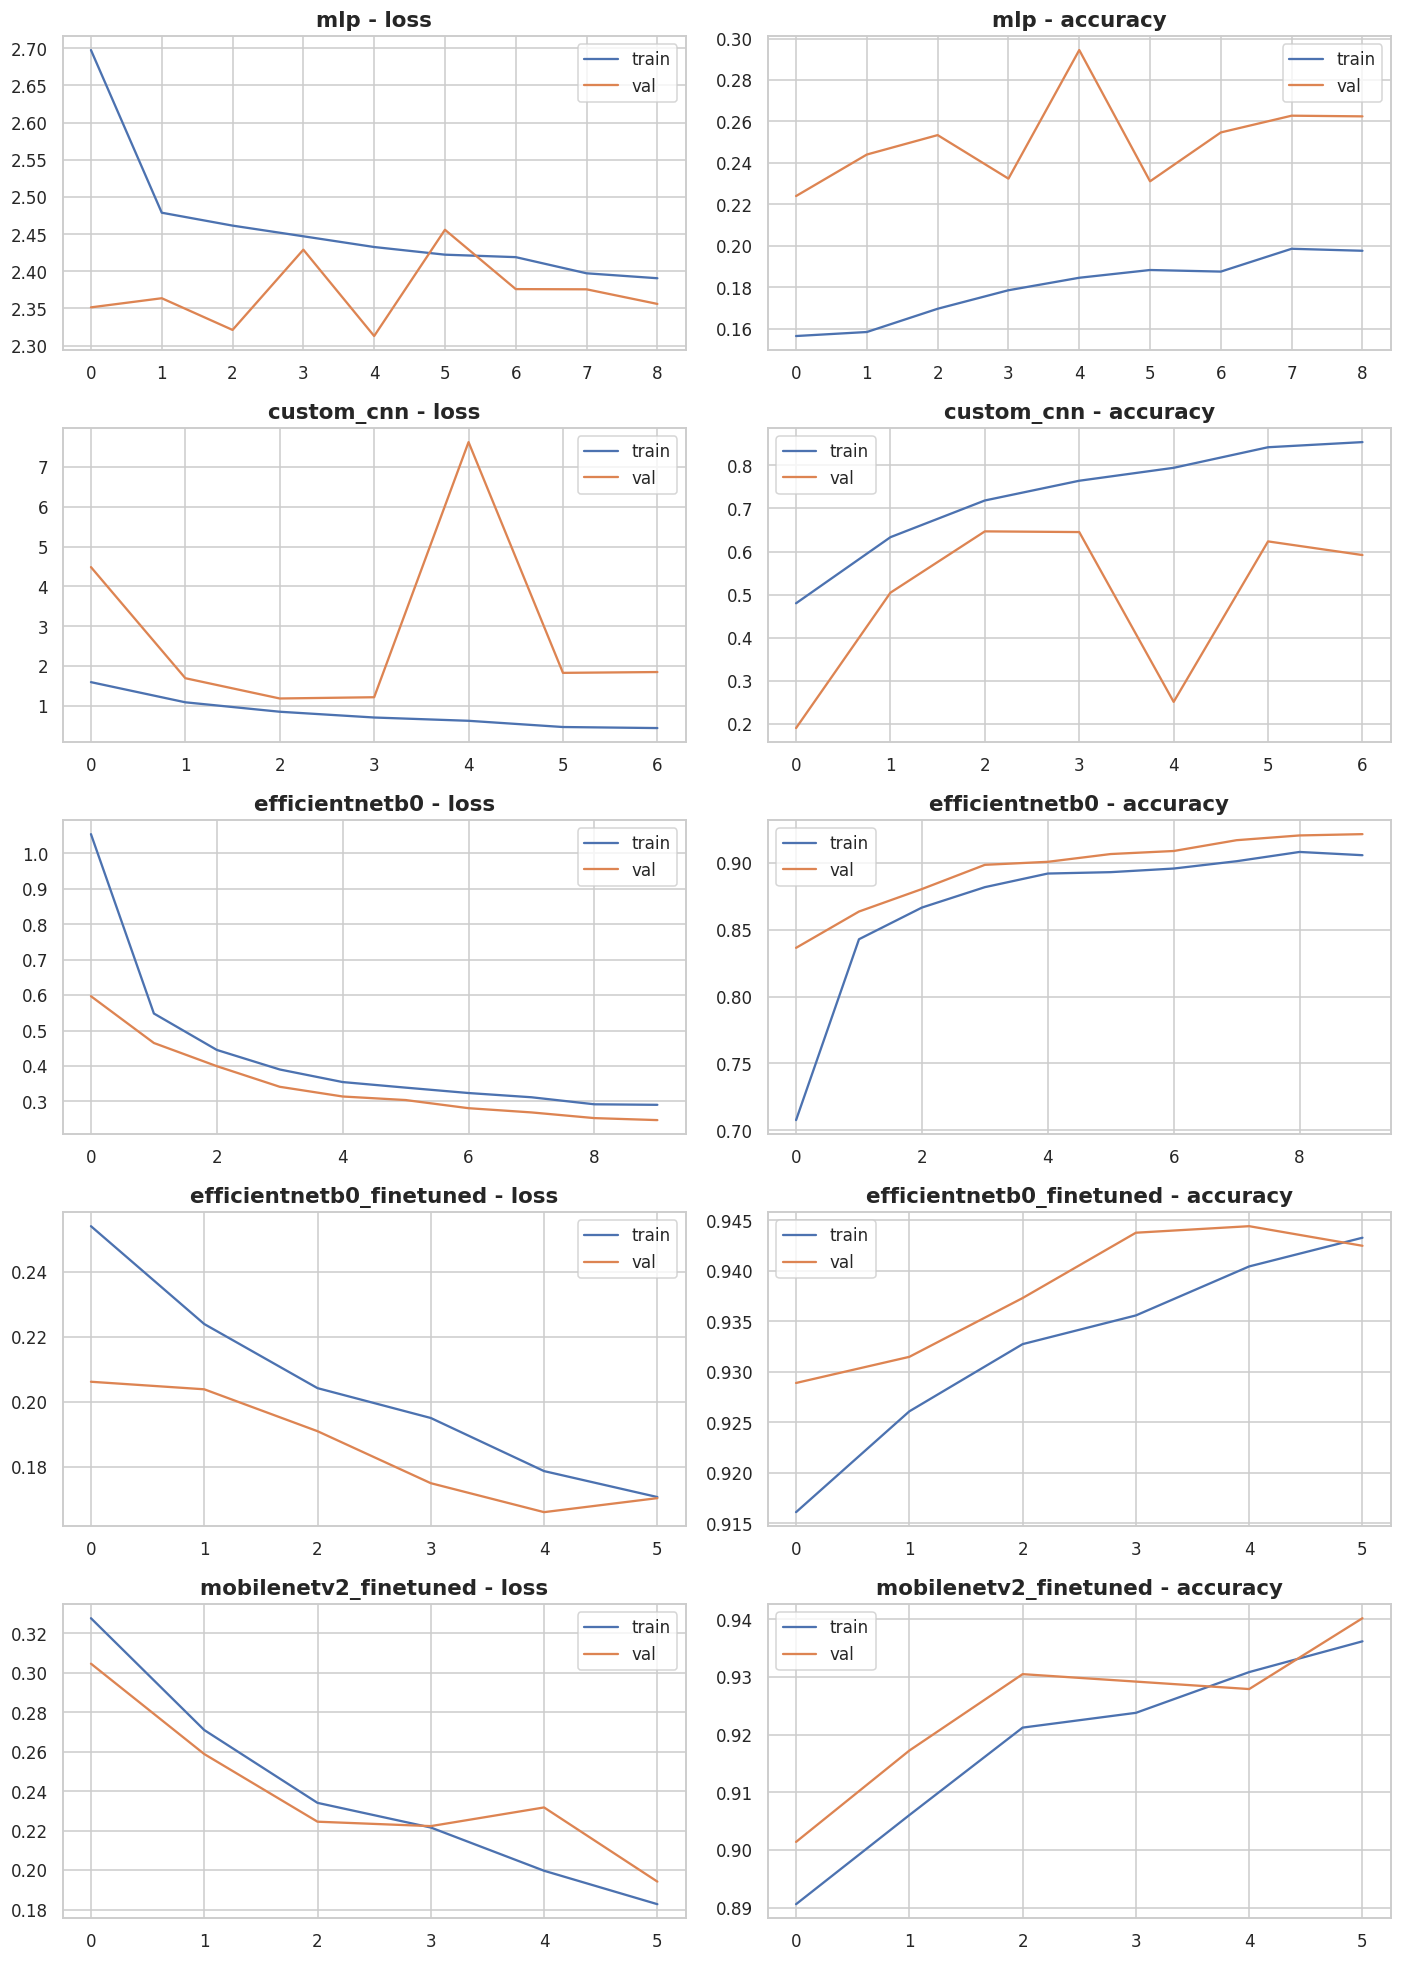

In [ ]:
def plot_histories(names):
    fig, axes = plt.subplots(len(names), 2, figsize=(13, 3.6 * len(names)), squeeze=False)
    for row, name in zip(axes, names):
        h = histories[name]
        row[0].plot(h["loss"], label="train"); row[0].plot(h["val_loss"], label="val")
        row[0].set_title(f"{name} - loss"); row[0].legend()
        row[1].plot(h["accuracy"], label="train"); row[1].plot(h["val_accuracy"], label="val")
        row[1].set_title(f"{name} - accuracy"); row[1].legend()
    plt.tight_layout(); plt.show()

plot_histories(list(histories))

## 10. Validation results and model selection

Every saved model is evaluated on the validation and test sets. The **final model is chosen on validation macro-F1 only**, and the test set is used afterwards just to report the final number, so there is no selection on the test data.

Fine-tuned EfficientNetB0 is the best model (validation macro-F1 0.974, test accuracy 97.7%). There is also a size and speed trade-off: the custom CNN is only 5.2 MB and the fastest (3.4 ms per image) while still reaching 95.8% test accuracy, which makes it attractive for very small deployments. The MLP is both the largest file and the worst model.

In [ ]:
y_true_val = np.concatenate([y.numpy() for _, y in val_ds])
y_true_test = np.concatenate([y.numpy() for _, y in test_ds])
results, preds = {}, {}

def evaluate_all():
    bx, _ = next(iter(test_ds))
    for path in sorted(pathlib.Path(MODEL_DIR).glob("*.keras")):
        name = path.stem
        if name in results or name == "final_model" or name.endswith("_noaug"):   # *_noaug = augmentation experiment (section 14)
            continue
        model = keras.models.load_model(path)
        row = {}
        for split, ds, yt in (("val", val_ds, y_true_val), ("test", test_ds, y_true_test)):
            prob = model.predict(ds, verbose=0)
            pred = prob.argmax(axis=1)
            p, r, f1, _ = precision_recall_fscore_support(yt, pred, average="macro", zero_division=0)
            row[f"{split}_acc"] = accuracy_score(yt, pred)
            row[f"{split}_f1"] = f1
            if split == "test":
                row["test_prec"], row["test_rec"] = p, r
                preds[name] = (pred, prob)
        model.predict(bx, verbose=0)                       # warm-up
        t0 = time.time()
        for _ in range(5):
            model.predict(bx, verbose=0)
        row["ms_per_image"] = (time.time() - t0) / 5 / len(bx) * 1000
        row["size_mb"] = os.path.getsize(path) / 1e6
        results[name] = row
        del model

evaluate_all()
results_df = pd.DataFrame(results).T.sort_values("val_f1", ascending=False)
display(results_df.round(4))
best_name = results_df.index[0]
print("Final model (chosen on VALIDATION macro-F1):", best_name)

,val_acc,val_f1,test_acc,test_f1,test_prec,test_rec,ms_per_image,size_mb
efficientnetb0_finetuned,0.9444,0.9437,0.9518,0.9505,0.9501,0.9537,5.1064,29.1560
mobilenetv2_finetuned,0.9402,0.9356,0.9379,0.9306,0.9336,0.9299,4.9949,21.9537
efficientnetb0,0.9215,0.9191,0.9279,0.9257,0.9306,0.9262,5.0981,17.2881
mobilenetv2,0.8959,0.8886,0.8933,0.8811,0.8937,0.8802,3.6435,9.8666
custom_cnn,0.6467,0.5987,0.6658,0.6165,0.7402,0.6083,2.9199,5.1963
mlp,0.2944,0.0997,0.2973,0.1050,0.0981,0.1791,2.5196,77.1793


Final model (chosen on VALIDATION macro-F1): efficientnetb0_finetuned


## 11. Test evaluation: classification report and confusion matrix

Final model on the untouched test set (8,138 images): accuracy 97.7%, macro precision 0.976, macro recall 0.971, macro F1 0.973. The normalized confusion matrix has a strong diagonal. The weakest classes are the ones with visually similar symptoms, mainly **Corn: Cercospora / Gray leaf spot** (F1 0.88) and some **Tomato** diseases. The table below the matrix lists the ten most frequent confusions.

                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot      0.993     0.993     0.993       150
                     Pepper__bell___healthy      0.995     1.000     0.998       221
                      Potato___Early_blight      0.980     1.000     0.990       150
                       Potato___Late_blight      0.973     0.953     0.963       150
                           Potato___healthy      0.885     1.000     0.939        23
                      Tomato_Bacterial_spot      0.977     0.925     0.950       319
                        Tomato_Early_blight      0.961     0.827     0.889       150
                         Tomato_Late_blight      0.931     0.951     0.941       285
                           Tomato_Leaf_Mold      0.985     0.930     0.957       143
                  Tomato_Septoria_leaf_spot      0.957     0.913     0.934       265
Tomato_Spider_mites_Two_spotted_spider_mite      0.967     0.921

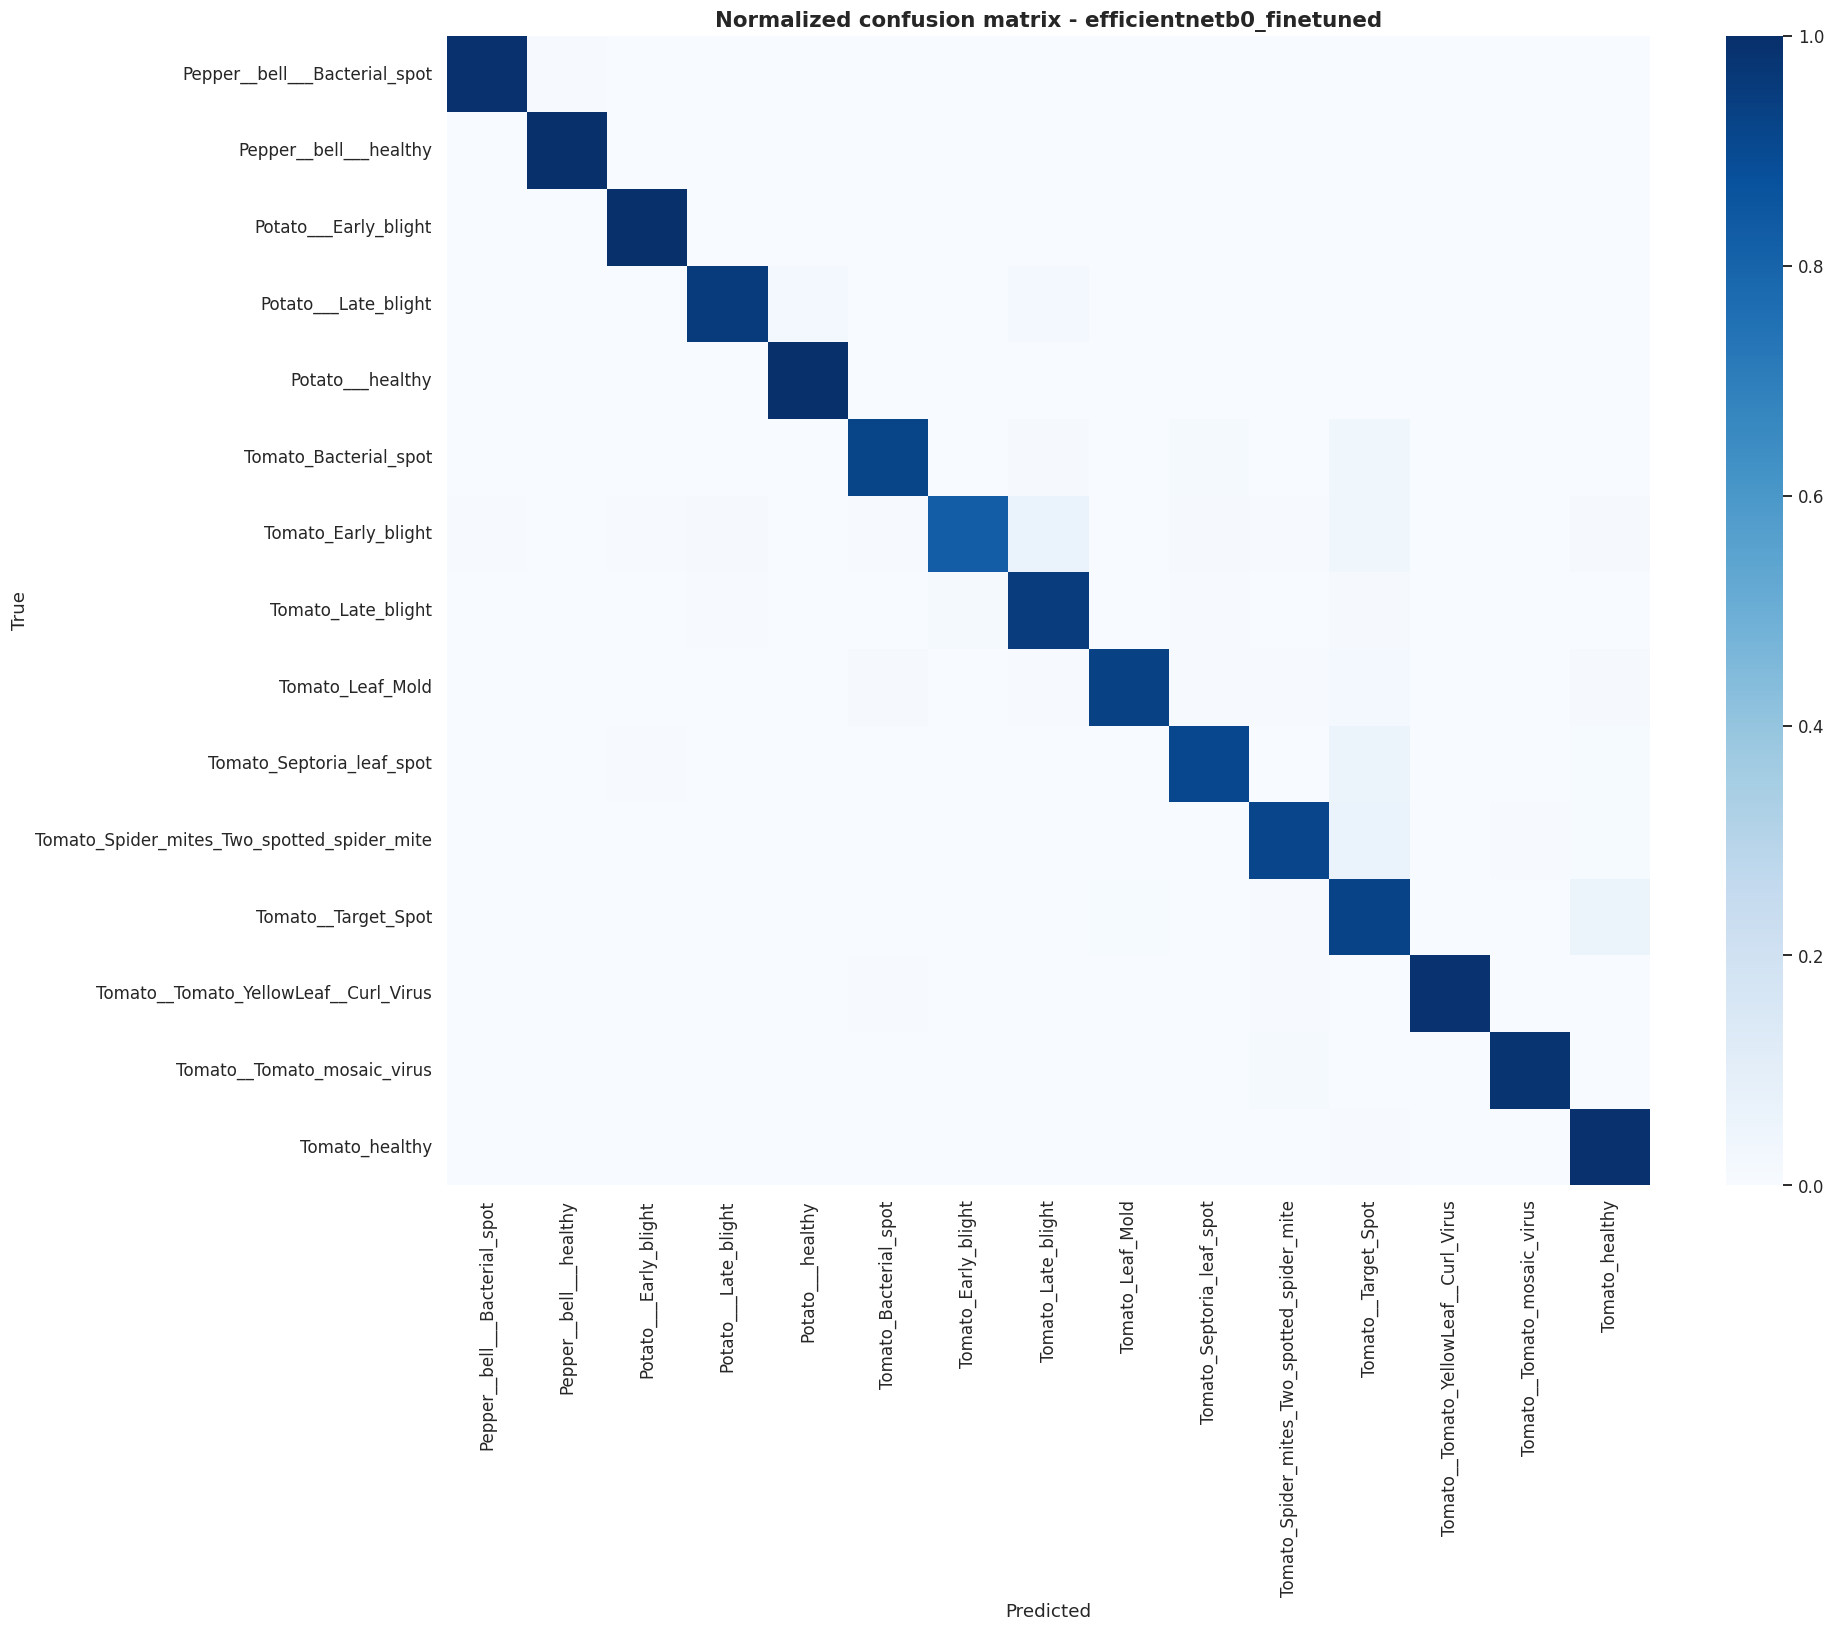

,true,predicted,count
0,Tomato_Spider_mites_Two_spotted_spider_mite,Tomato__Target_Spot,17
1,Tomato_Septoria_leaf_spot,Tomato__Target_Spot,15
2,Tomato_Bacterial_spot,Tomato__Target_Spot,13
3,Tomato__Target_Spot,Tomato_healthy,12
4,Tomato_Early_blight,Tomato_Late_blight,10
5,Tomato_Bacterial_spot,Tomato_Septoria_leaf_spot,6
6,Tomato_Early_blight,Tomato__Target_Spot,6
7,Tomato_Late_blight,Tomato_Early_blight,5
8,Potato___Late_blight,Tomato_Late_blight,4
9,Tomato_Bacterial_spot,Tomato_Late_blight,4


In [ ]:
shutil.copy(f"{MODEL_DIR}/{best_name}.keras", f"{MODEL_DIR}/final_model.keras")
y_pred_best, y_prob_best = preds[best_name]

print(classification_report(y_true_test, y_pred_best, labels=np.arange(NUM_CLASSES),
                            target_names=class_names, digits=3))

cm = confusion_matrix(y_true_test, y_pred_best, labels=np.arange(NUM_CLASSES))
cm_norm = cm / cm.sum(axis=1, keepdims=True)
plt.figure(figsize=(18, 15))
sns.heatmap(cm_norm, cmap="Blues", vmin=0, vmax=1, xticklabels=class_names, yticklabels=class_names)
plt.title(f"Normalized confusion matrix - {best_name}")
plt.xlabel("Predicted"); plt.ylabel("True")
plt.tight_layout(); plt.show()

off = cm.copy(); np.fill_diagonal(off, 0)
pairs = [(class_names[i], class_names[j], int(off[i, j])) for i, j in zip(*np.nonzero(off))]
display(pd.DataFrame(sorted(pairs, key=lambda t: -t[2])[:10], columns=["true", "predicted", "count"]))

## 12. Error analysis

The final model makes **186 mistakes out of 8,138 test images (2.29%)**. The grid shows the most confident mistakes and the bar chart shows the ten classes with the highest error rate.

- Most errors are between classes of the **same crop with similar-looking lesions**: Tomato bacterial spot vs Septoria leaf spot, Tomato spider mites vs target spot, Tomato early blight vs late blight, and Corn Cercospora (gray leaf spot) vs Northern leaf blight.
- Confidently wrong predictions deserve a manual look: some of them may be ambiguous or noisy labels rather than model failures.
- Improvement ideas: more or higher-resolution data for the confused pairs, targeted augmentation, class weights, or a larger input size.

149 wrong out of 3094 (4.82%)


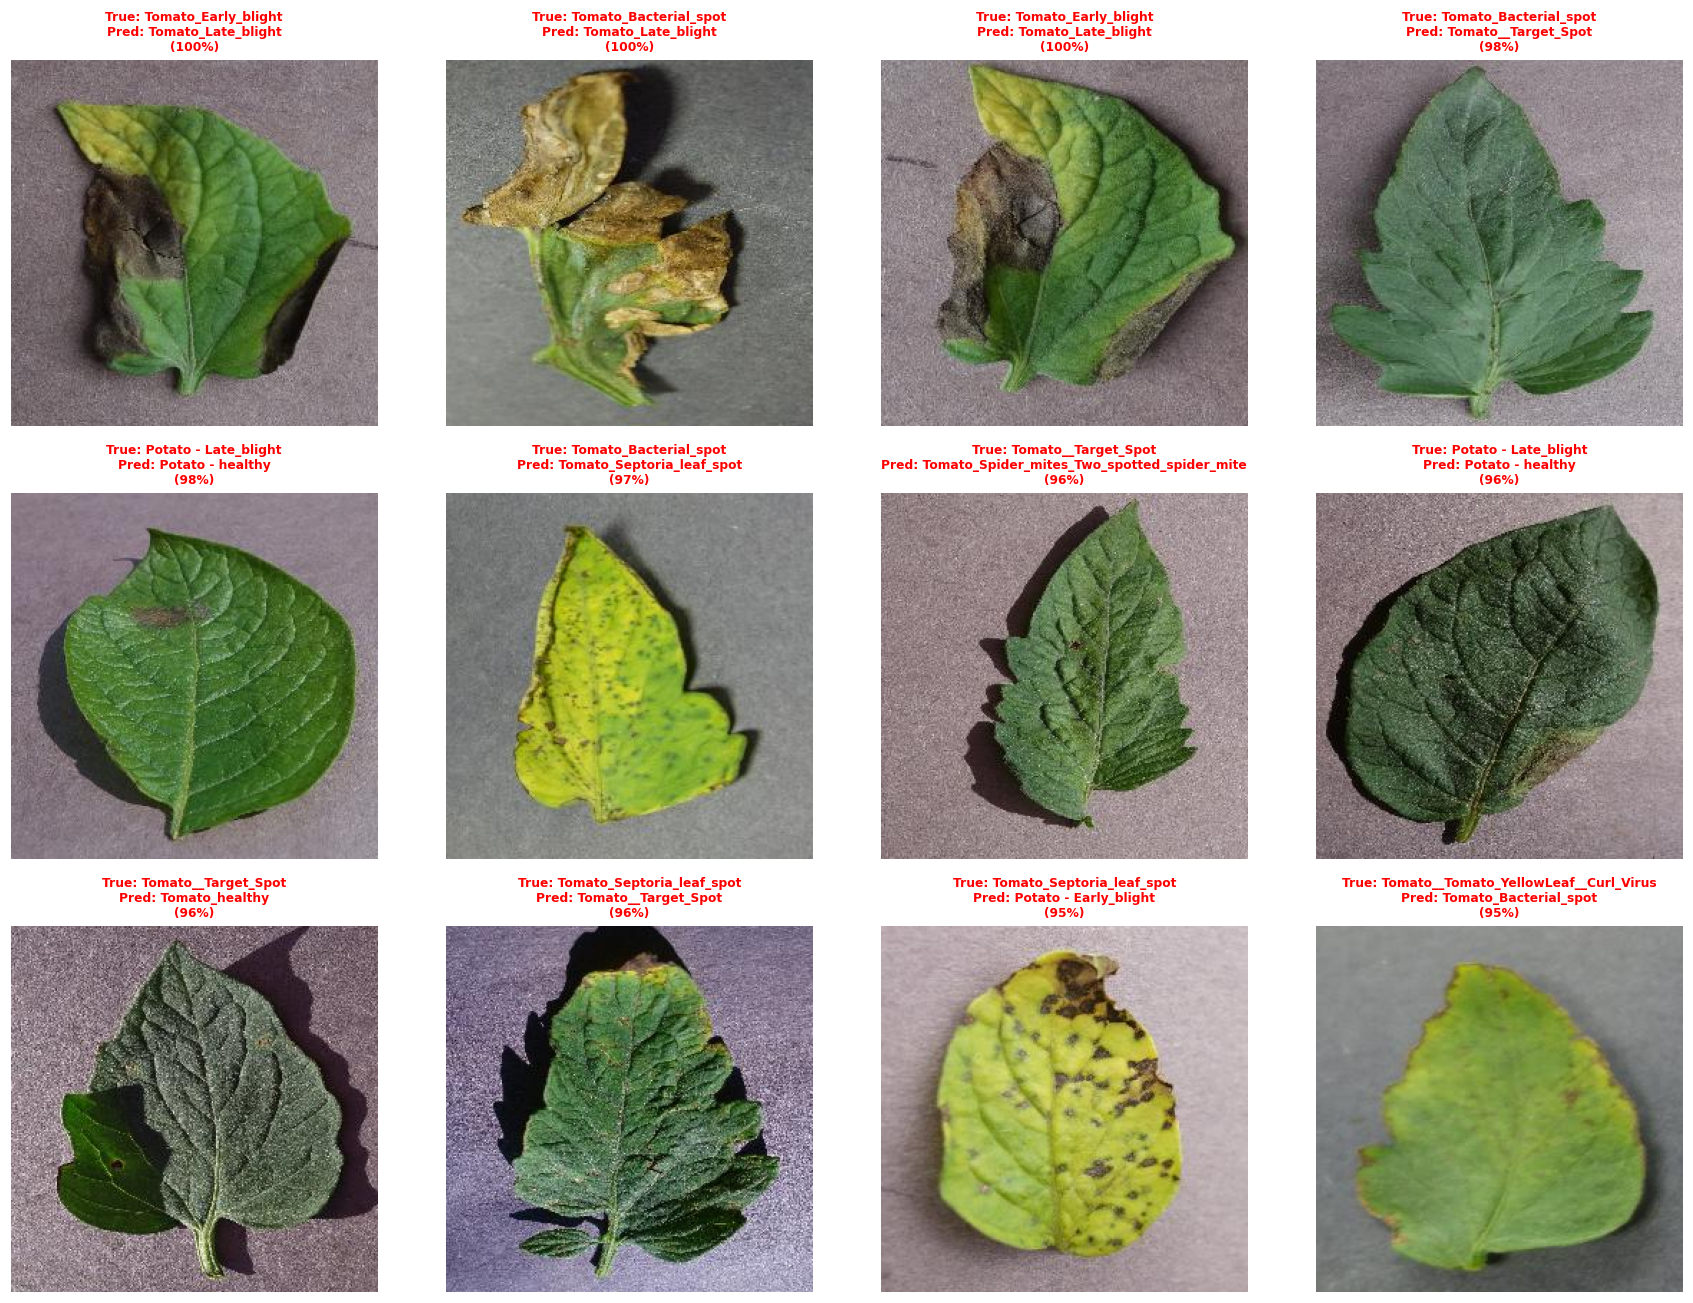

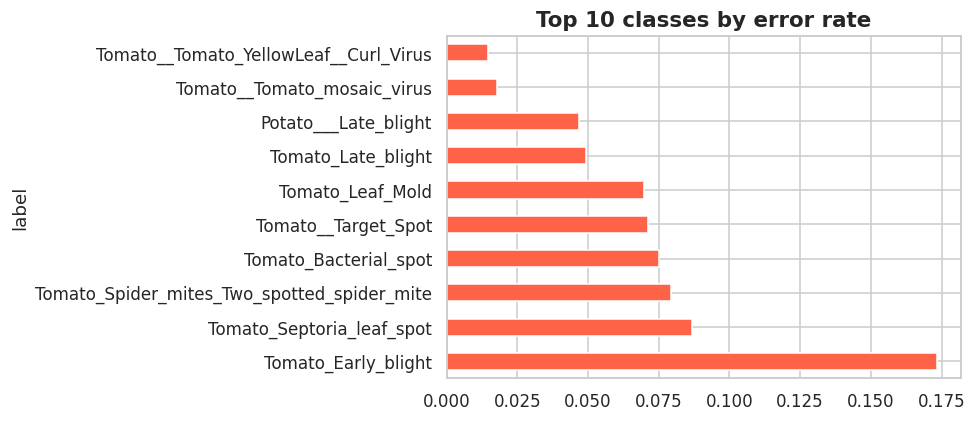

In [ ]:
test_eval = test_df.reset_index(drop=True).copy()
assert (test_eval["label_idx"].values == y_true_test).all()
test_eval["pred"] = [class_names[i] for i in y_pred_best]
test_eval["confidence"] = y_prob_best.max(axis=1)
test_eval["correct"] = y_pred_best == y_true_test
errors = test_eval[~test_eval["correct"]]
print(f"{len(errors)} wrong out of {len(test_eval)} ({len(errors) / len(test_eval):.2%})")

show = errors.sort_values("confidence", ascending=False).head(12)
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
for ax in axes.flat:
    ax.axis("off")
for ax, (_, r) in zip(axes.flat, show.iterrows()):
    ax.imshow(Image.open(r["path"]))
    ax.set_title(f"True: {r['label'].replace('___', ' - ')}\nPred: {r['pred'].replace('___', ' - ')}\n({r['confidence']:.0%})",
                 fontsize=8, color="red")
plt.tight_layout(); plt.show()

err_rate = (1 - test_eval.groupby("label")["correct"].mean()).sort_values(ascending=False)
err_rate.head(10).plot.barh(color="tomato", figsize=(9, 4), title="Top 10 classes by error rate")
plt.tight_layout(); plt.show()

## 13. Explainability with Grad-CAM

Grad-CAM shows **where the model looked** when it made a prediction. Warm colours mark the regions that increased the score of the predicted class most. For correct predictions the heat should sit on the leaf and the lesions rather than on the background. For the most confident mistakes the maps help to see whether the model focused on something misleading.

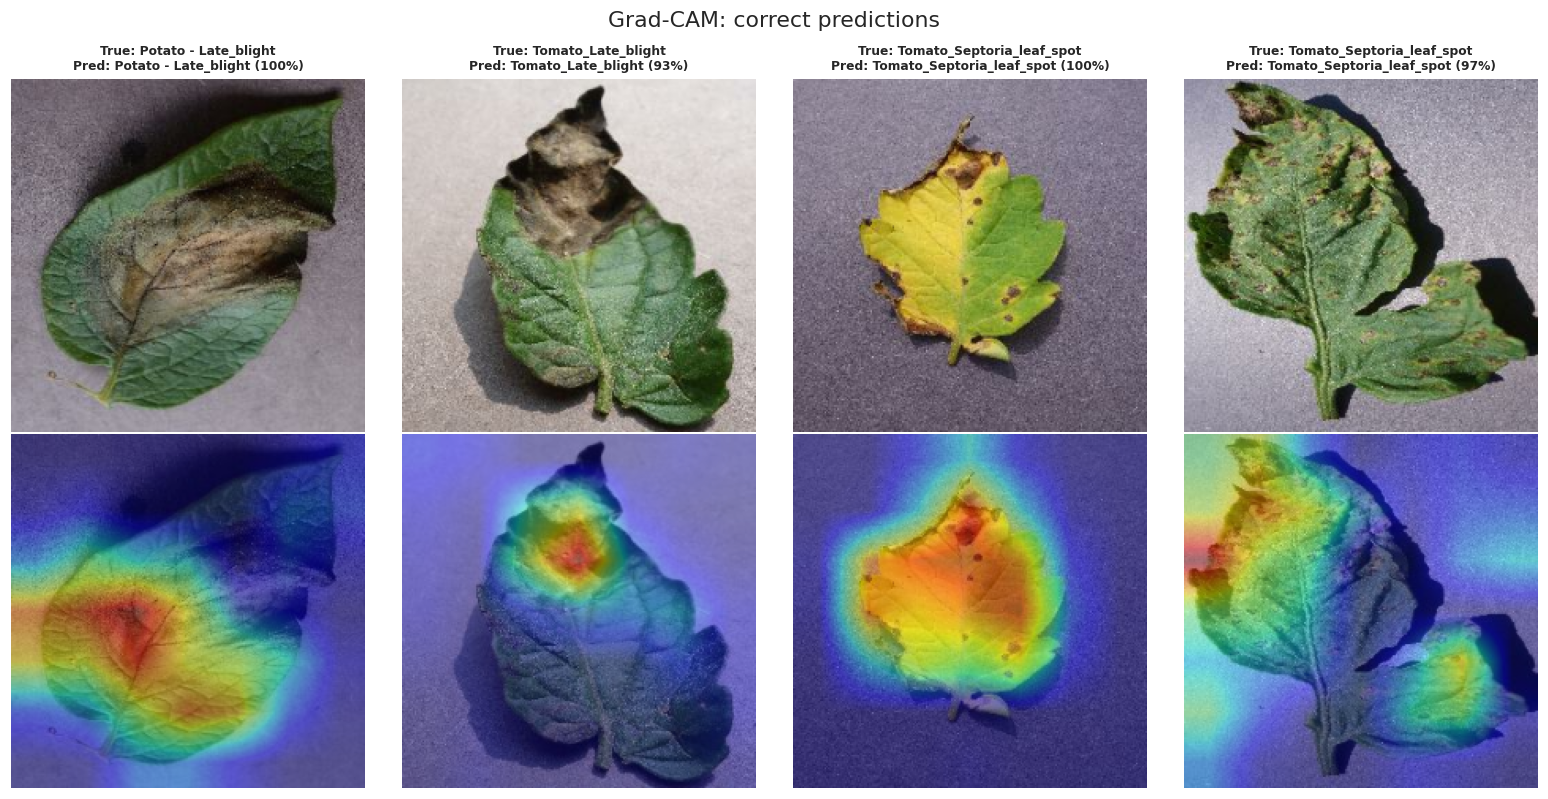

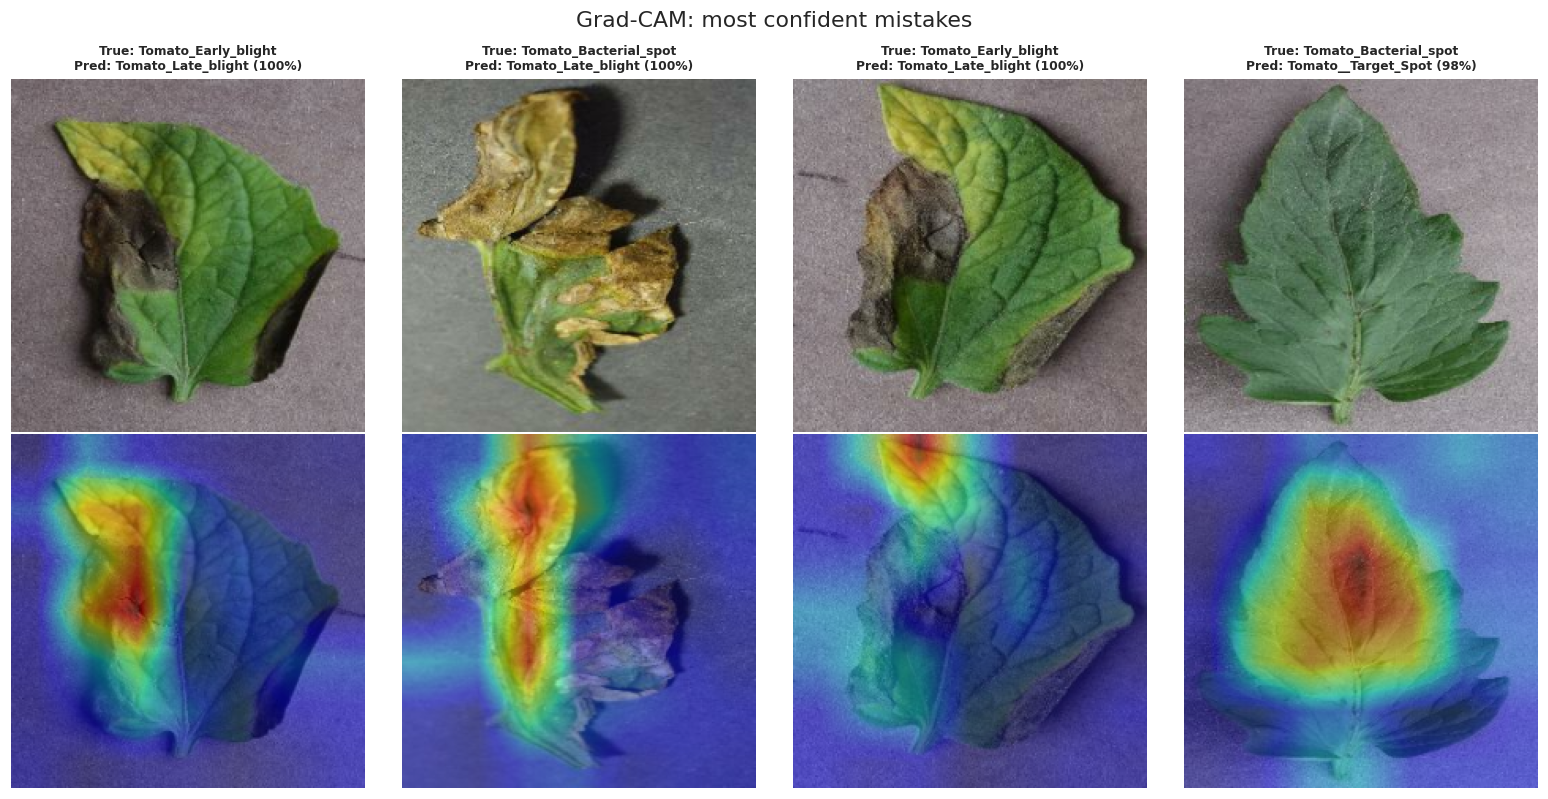

In [ ]:
final_model = keras.models.load_model(f"{MODEL_DIR}/final_model.keras")
assert get_base(final_model).count_params() > 1_000_000, "final model should be a transfer model"

def grad_cam(model, img_batch):
    base = get_base(model)
    x = tf.convert_to_tensor(img_batch)
    with tf.GradientTape() as tape:
        for layer in model.layers:
            if isinstance(layer, keras.layers.InputLayer):
                continue
            if layer is base:
                x = base(x, training=False)
                conv_out = x
                tape.watch(conv_out)
            else:
                x = layer(x, training=False)
        pred = x
        class_idx = tf.argmax(pred[0])
        score = pred[:, class_idx]
    grads = tape.gradient(score, conv_out)
    weights = tf.reduce_mean(grads, axis=(0, 1, 2))
    cam = tf.nn.relu(tf.reduce_sum(conv_out[0] * weights, axis=-1))
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    return cam.numpy(), int(class_idx), float(tf.reduce_max(pred[0]))

def show_gradcam(rows, title):
    n = len(rows)
    fig, axes = plt.subplots(2, n, figsize=(3.6 * n, 7.4), squeeze=False)
    for c, (_, r) in enumerate(rows.iterrows()):
        img, _ = load_image_u8(r["path"], 0)
        img = img.numpy()
        cam, idx, conf = grad_cam(final_model, tf.cast(img, tf.float32)[None])
        cam = tf.image.resize(cam[..., None], IMG_SIZE).numpy()[..., 0]
        axes[0, c].imshow(img); axes[0, c].axis("off")
        axes[0, c].set_title(f"True: {r['label'].replace('___', ' - ')}\nPred: {class_names[idx].replace('___', ' - ')} ({conf:.0%})", fontsize=8)
        axes[1, c].imshow(img); axes[1, c].imshow(cam, cmap="jet", alpha=0.45); axes[1, c].axis("off")
    plt.suptitle(title); plt.tight_layout(); plt.show()

show_gradcam(test_eval[test_eval["correct"]].sample(4, random_state=SEED), "Grad-CAM: correct predictions")
show_gradcam(errors.sort_values("confidence", ascending=False).head(4), "Grad-CAM: most confident mistakes")

## 14. Augmentation experiment

All models so far use data augmentation **inside the model** (random rotation up to 36 degrees, horizontal flip, zoom up to 15%, brightness change up to 20%). It is active only during training. This section checks whether it really helps:

1. **What it does:** one training image and several augmented versions of it.
2. **Experiment:** train the same frozen MobileNetV2 again **without** augmentation (same epochs, optimizer and learning rate) and compare it with the augmented one.
3. **Robustness test:** both models are evaluated on a 3,000-image test subset that is perturbed on purpose (darker, brighter, rotated, zoomed, noisy). Augmentation is mainly expected to help here, because the clean test set looks very much like the training set.

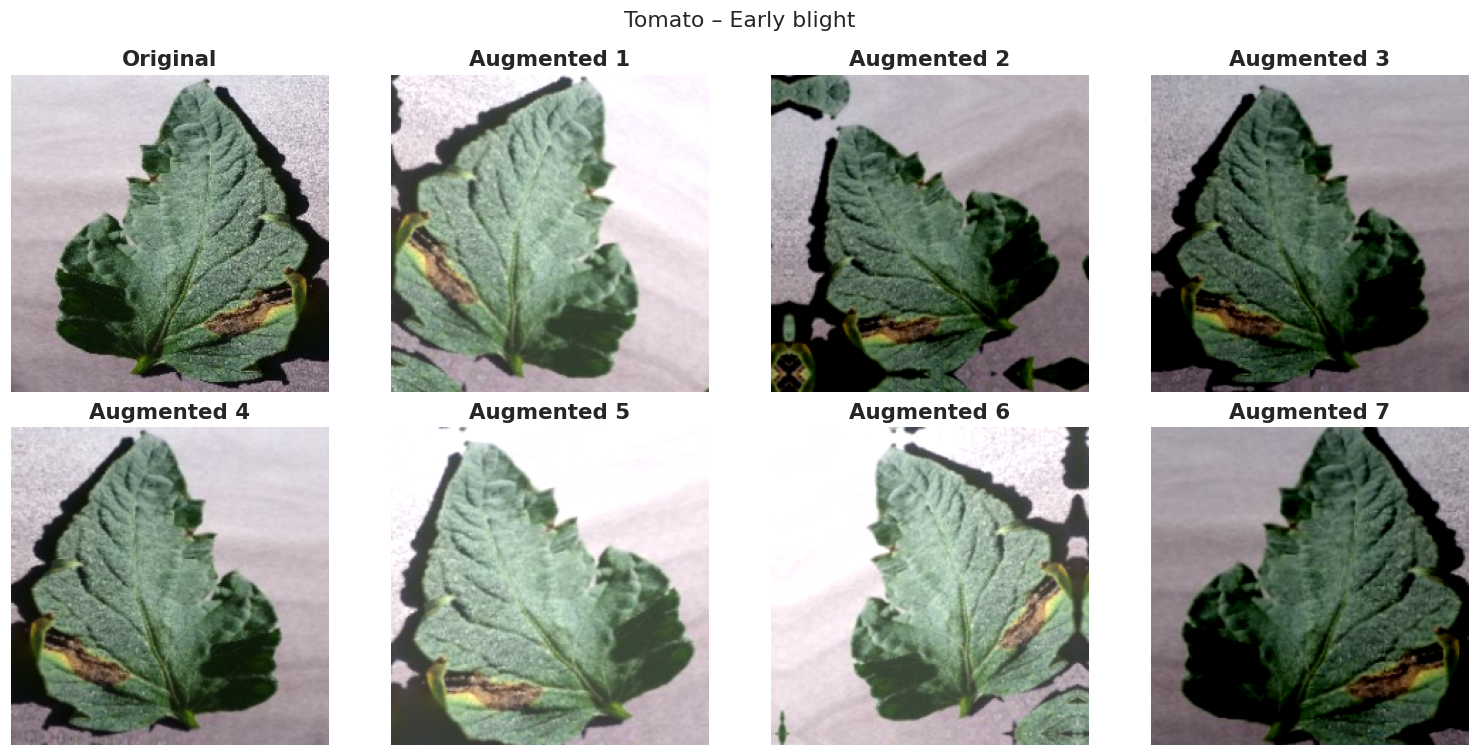

In [ ]:
# 14.1 What the augmentation does to one training image
row = train_df.sample(1, random_state=SEED).iloc[0]
img_u8, _ = load_image_u8(row["path"], 0)
img = tf.cast(img_u8, tf.float32)[None]
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for k, ax in enumerate(axes.flat):
    out = img if k == 0 else augmentation(img, training=True)
    ax.imshow(np.clip(out[0].numpy(), 0, 255).astype("uint8")); ax.axis("off")
    ax.set_title("Original" if k == 0 else f"Augmented {k}")
plt.suptitle(pretty(row["label"])); plt.tight_layout(); plt.show()

In [ ]:
# 14.2 Train MobileNetV2 (frozen) WITHOUT augmentation (skipped if it already exists)
RUN_AUG_EXPERIMENT = True
noaug_name = "mobilenetv2_noaug"
if RUN_AUG_EXPERIMENT and not os.path.exists(f"{MODEL_DIR}/{noaug_name}.keras"):
    noaug_model = build_transfer_model("mobilenetv2", NUM_CLASSES, augment=False)
    train_model(noaug_name, noaug_model, train_ds)
else:
    print("skipped (already trained or RUN_AUG_EXPERIMENT = False)")

Epoch 1/10
452/452 ━━━━━━━━━━━━━━━━━━━━ 100s 163ms/step - accuracy: 0.7296 - loss: 0.8704 - val_accuracy: 0.8697 - val_loss: 0.4414 - learning_rate: 0.0010
Epoch 2/10
452/452 ━━━━━━━━━━━━━━━━━━━━ 21s 45ms/step - accuracy: 0.8626 - loss: 0.4296 - val_accuracy: 0.8995 - val_loss: 0.3427 - learning_rate: 0.0010
Epoch 3/10
452/452 ━━━━━━━━━━━━━━━━━━━━ 19s 41ms/step - accuracy: 0.8881 - loss: 0.3493 - val_accuracy: 0.9069 - val_loss: 0.3065 - learning_rate: 0.0010
Epoch 4/10
452/452 ━━━━━━━━━━━━━━━━━━━━ 19s 41ms/step - accuracy: 0.9000 - loss: 0.3101 - val_accuracy: 0.9169 - val_loss: 0.2765 - learning_rate: 0.0010
Epoch 5/10
452/452 ━━━━━━━━━━━━━━━━━━━━ 19s 40ms/step - accuracy: 0.9054 - loss: 0.2855 - val_accuracy: 0.9140 - val_loss: 0.2751 - learning_rate: 0.0010
Epoch 6/10
452/452 ━━━━━━━━━━━━━━━━━━━━ 21s 45ms/step - accuracy: 0.9129 - loss: 0.2675 - val_accuracy: 0.9218 - val_loss: 0.2590 - learning_rate: 0.0010
Epoch 7/10
452/452 ━━━━━━━━━━━━━━━━━━━━ 19s 40ms/step - accuracy: 0.9175 -

,with augmentation,without augmentation
clean,89.27%,92.33%
darker (x0.6),85.80%,88.90%
brighter (x1.4),87.63%,90.90%
rotated 30 deg,89.27%,86.23%
zoomed in 30%,83.73%,76.67%
gaussian noise,65.87%,61.67%


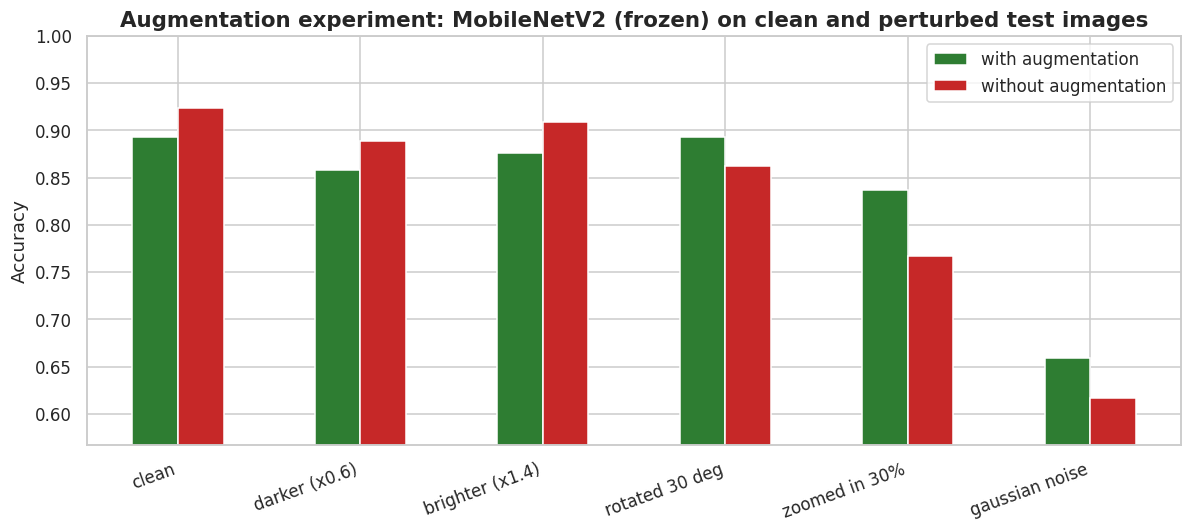

Clean images: augmentation changes accuracy by -3.07 points
Perturbed images (average of the 5 perturbations): +1.59 points
Largest gain: zoomed in 30% (+7.07 points) | smallest: brighter (x1.4) (-3.27 points)


In [ ]:
# 14.3 Clean vs perturbed test images: with augmentation vs without
pair = {"with augmentation": "mobilenetv2", "without augmentation": noaug_name}
if not all(os.path.exists(f"{MODEL_DIR}/{n}.keras") for n in pair.values()):
    print("Both models are needed: run 14.2 first.")
else:
    sub_df = test_df.sample(3000, random_state=SEED).reset_index(drop=True)
    sub_ds = make_dataset(sub_df)                                   # no cache, 3,000 images only
    rot = layers.RandomRotation((30 / 360, 30 / 360), fill_mode="reflect")     # fixed 30 degrees
    zoom = layers.RandomZoom((-0.3, -0.3), fill_mode="reflect")                # fixed 30% zoom in
    perturbations = {
        "clean": lambda x: x,
        "darker (x0.6)": lambda x: tf.clip_by_value(x * 0.6, 0, 255),
        "brighter (x1.4)": lambda x: tf.clip_by_value(x * 1.4, 0, 255),
        "rotated 30 deg": lambda x: rot(x, training=True),
        "zoomed in 30%": lambda x: zoom(x, training=True),
        "gaussian noise": lambda x: tf.clip_by_value(x + tf.random.normal(tf.shape(x), stddev=20.0), 0, 255),
    }

    def accuracy_under(model, fn):
        correct = total = 0
        for xb, yb in sub_ds:
            pred = model.predict_on_batch(fn(xb)).argmax(axis=1)
            correct += int((pred == yb.numpy()).sum()); total += len(yb)
        return correct / total

    aug_rows = {}
    for label, name in pair.items():
        m = keras.models.load_model(f"{MODEL_DIR}/{name}.keras")
        aug_rows[label] = {p: accuracy_under(m, fn) for p, fn in perturbations.items()}
        del m
    aug_df = pd.DataFrame(aug_rows)
    display((aug_df * 100).round(2).style.format("{:.2f}%"))

    aug_df.plot.bar(figsize=(11, 5), color=["#2E7D32", "#C62828"])
    plt.ylabel("Accuracy"); plt.ylim(max(0, aug_df.values.min() - 0.05), 1.0)
    plt.title("Augmentation experiment: MobileNetV2 (frozen) on clean and perturbed test images")
    plt.xticks(rotation=20, ha="right"); plt.tight_layout(); plt.show()

    gain = (aug_df["with augmentation"] - aug_df["without augmentation"]) * 100
    print(f"Clean images: augmentation changes accuracy by {gain['clean']:+.2f} points")
    print(f"Perturbed images (average of the 5 perturbations): {gain.drop('clean').mean():+.2f} points")
    print(f"Largest gain: {gain.idxmax()} ({gain.max():+.2f} points) | smallest: {gain.idxmin()} ({gain.min():+.2f} points)")

**How to read the result.** On the clean test images the two models are usually close, because the test set comes from the same controlled photo setup as the training set. The real value of augmentation shows up on the perturbed images: a model that has seen rotated, zoomed and brightness-shifted leaves during training loses less accuracy when the conditions change. This matters for the real-photo test below and for the Streamlit app, where users take photos in very different conditions. If the gain on perturbed images is small, the main remaining weakness is the background and domain gap, not geometry or brightness.

## 15. Testing on real leaf photos (domain gap)

PlantVillage images are single leaves on a uniform background under controlled light. Real photos (a leaf in the field, soil or hands in the background, shadows, several leaves, phone cameras) look different, which is called the **domain gap**. A model that scores 97.7% on the test split can be noticeably worse here, and that is expected.

**How to use this section**

1. Put your own leaf photos in `WORK_DIR/real_photos/`.
2. Optional: name a file like `Tomato___Early_blight_01.jpg` (the exact class name from `class_names`, then anything) and the accuracy is computed automatically. Files with other names are still predicted, just without a score.
3. Run the cells and look at the predictions, the confidence, the low-confidence warnings (below 70%, the same threshold as the app) and the Grad-CAM maps.

For a fair test use photos of the 14 supported crops only, one leaf per photo, in good light.

In [ ]:
REAL_DIR = pathlib.Path(f"{WORK_DIR}/real_photos")
REAL_DIR.mkdir(parents=True, exist_ok=True)
real_files = sorted(p for p in REAL_DIR.rglob("*") if p.suffix.lower() in IMG_EXT)
print(f"{len(real_files)} real photos found in {REAL_DIR}")
if not real_files:
    print(f"Add photos to {REAL_DIR} on Google Drive and re-run this cell.")

0 real photos found in /content/drive/MyDrive/plant_disease/real_photos
Add photos to /content/drive/MyDrive/plant_disease/real_photos on Google Drive and re-run this cell.


In [ ]:
LOW_CONF = 0.70            # same threshold as the Streamlit app

def true_label_from_name(path):
    matches = [c for c in class_names if path.stem.startswith(c)]
    return max(matches, key=len) if matches else None

real_cache, real_rows = {}, []
for p in real_files:
    img = Image.open(p).convert("RGB")
    x = np.asarray(img.resize(IMG_SIZE), dtype="float32")[None]          # same preprocessing as the app
    probs = final_model.predict(x, verbose=0)[0]
    top = probs.argsort()[::-1][:3]
    real_cache[p] = (img, x, probs, top)
    real_rows.append({"file": p.name, "true": true_label_from_name(p), "pred": class_names[top[0]],
                      "confidence": float(probs[top[0]]), "top2": class_names[top[1]],
                      "top3": class_names[top[2]], "low_conf": bool(probs[top[0]] < LOW_CONF)})
real_df = pd.DataFrame(real_rows)
if len(real_df):
    real_df["correct"] = np.where(real_df["true"].notna(), real_df["true"] == real_df["pred"], np.nan)
    display(real_df.round(3))

In [ ]:
def show_real_predictions(max_n=12, cols=4):
    files = real_files[:max_n]
    if not files:
        print("No real photos to show."); return
    rows_n = int(np.ceil(len(files) / cols))
    fig, axes = plt.subplots(rows_n, cols, figsize=(4.2 * cols, 4.8 * rows_n), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, p in zip(axes.flat, files):
        img, x, probs, top = real_cache[p]
        truth = true_label_from_name(p)
        pred = class_names[top[0]]
        color = "black" if truth is None else ("green" if pred == truth else "red")
        low = "  (low confidence)" if probs[top[0]] < LOW_CONF else ""
        ax.imshow(img)
        ax.set_title(f"{pred.replace('___', ' - ')}\n{probs[top[0]]:.0%}{low}", fontsize=8, color=color)
    plt.tight_layout(); plt.show()

show_real_predictions()

No real photos to show.


In [ ]:
def show_real_gradcam(max_n=6):
    files = real_files[:max_n]
    if not files:
        print("No real photos to show."); return
    fig, axes = plt.subplots(2, len(files), figsize=(3.6 * len(files), 7.4), squeeze=False)
    for c, p in enumerate(files):
        img, x, probs, top = real_cache[p]
        cam, idx, conf = grad_cam(final_model, tf.convert_to_tensor(x))
        cam = tf.image.resize(cam[..., None], IMG_SIZE).numpy()[..., 0]
        base_img = np.asarray(img.resize(IMG_SIZE))
        axes[0, c].imshow(base_img); axes[0, c].axis("off")
        axes[0, c].set_title(f"{class_names[idx].replace('___', ' - ')} ({conf:.0%})", fontsize=8)
        axes[1, c].imshow(base_img); axes[1, c].imshow(cam, cmap="jet", alpha=0.45); axes[1, c].axis("off")
    plt.suptitle("Grad-CAM on real photos"); plt.tight_layout(); plt.show()

show_real_gradcam()

No real photos to show.


In [ ]:
# Summary of the real-photo test
if len(real_df):
    print(f"Photos: {len(real_df)} | mean confidence: {real_df['confidence'].mean():.1%} | "
          f"below {LOW_CONF:.0%} confidence: {int(real_df['low_conf'].sum())} ({real_df['low_conf'].mean():.0%})")
    known = real_df[real_df["true"].notna()]
    if len(known):
        print(f"Accuracy on {len(known)} photos with a known label: {known['correct'].mean():.1%} "
              f"(PlantVillage test split: {results_df.loc[best_name, 'test_acc']:.1%})")
    else:
        print("No file names matched a class name, so no accuracy is computed (see the instructions above).")
else:
    print("No real photos were found.")

No real photos were found.


**Discussion: the domain gap.** The model was trained only on clean, single-leaf, uniform-background photos. On real photos, expect lower confidence and more mistakes, especially with cluttered backgrounds, strong shadows, several leaves in one frame, or crops and diseases outside the 38 classes. The Grad-CAM maps help to diagnose this: if the heat sits on the background or on a hand instead of the leaf, the model is using the wrong cues. The low-confidence warning in the app is the practical safeguard.

Realistic ways to close the gap: add field images (for example the PlantDoc dataset) to training, add background and lighting augmentation, crop or segment the leaf before classification, and calibrate the confidence threshold on real photos.

## 16. Streamlit app (deliverable)

> The app is written to `WORK_DIR/streamlit_app` on Google Drive. If you change `WORK_DIR`, also change the path on the first line of the `%%writefile` cell below.

The app lets a user upload or capture a leaf photo and shows the crop, healthy / disease label, confidence, the top-3 probabilities, a low-confidence warning, and the Grad-CAM map. The cells below create the folder `streamlit_app/` with the final model, the class names, `requirements.txt`, a `README.md`, a few demo images from the test split, and `app.py`. A headless smoke test then checks that the app starts without errors and the folder is zipped for download.

**To run it on your own machine:** download `streamlit_app.zip` from the Output tab, unzip it, then run `pip install -r requirements.txt` followed by `streamlit run app.py` (details in the README inside the zip). Use a TensorFlow version compatible with the one pinned in `requirements.txt`, because a `.keras` file saved with a newer Keras may not load in an older one.

In [ ]:
APP_DIR = f"{WORK_DIR}/streamlit_app"
os.makedirs(APP_DIR, exist_ok=True)
shutil.copy(f"{MODEL_DIR}/final_model.keras", APP_DIR)
json.dump(class_names, open(f"{APP_DIR}/class_names.json", "w"))
open(f"{APP_DIR}/requirements.txt", "w").write(
    f"streamlit\ntensorflow=={tf.__version__}\npillow\nnumpy\npandas\nmatplotlib\n")
# a few demo images from the TEST split (one per class, correctly classified) for trying the app
demo_dir = f"{APP_DIR}/sample_images"
os.makedirs(demo_dir, exist_ok=True)
demo = test_eval[test_eval["correct"]].groupby("label").head(1).sample(8, random_state=SEED)
for _, r in demo.iterrows():
    shutil.copy(r["path"], f"{demo_dir}/{r['label']}{pathlib.Path(r['path']).suffix}")

open(f"{APP_DIR}/README.md", "w").write(f"""# Plant Leaf Disease Detection (Streamlit app)

Predicts the crop and whether a leaf is healthy or which disease it has ({NUM_CLASSES} PlantVillage classes).

## Run locally
1. Unzip this folder and open a terminal inside it.
2. (Recommended) create a virtual environment: `python -m venv .venv` then activate it.
3. Install the dependencies: `pip install -r requirements.txt`
4. Start the app: `streamlit run app.py`  (it opens at http://localhost:8501)

## Files
- `app.py`: the Streamlit app
- `final_model.keras`: the trained model (fine-tuned {best_name})
- `class_names.json`: the {NUM_CLASSES} class names in the order used by the model
- `sample_images/`: demo leaf images from the test split

## Notes
- The model was saved with TensorFlow {tf.__version__} / Keras {keras.__version__}. If loading fails, install the same versions.
- Best results: one leaf, close-up, good light. The model was trained on clean-background photos, so cluttered field photos can be less accurate.
- Educational project. Not a substitute for professional agronomic advice.
""")
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

TensorFlow 2.21.0 | Keras 3.13.2


In [ ]:
%%writefile /content/drive/MyDrive/plant_disease/streamlit_app/app.py
import json
import re
import numpy as np
import pandas as pd
import streamlit as st
import tensorflow as tf
from tensorflow import keras
from PIL import Image
import matplotlib
matplotlib.use("Agg")
import matplotlib.cm as cm

IMG_SIZE = (224, 224)
st.set_page_config(page_title="Plant Leaf Disease Detection", page_icon="🌿", layout="wide")

@st.cache_resource
def load_assets():
    model = keras.models.load_model("final_model.keras")
    with open("class_names.json") as f:
        class_names = json.load(f)
    base = max((l for l in model.layers if isinstance(l, keras.Model)), key=lambda l: l.count_params())
    return model, class_names, base

model, class_names, base = load_assets()

def pretty(label):
    # Works for "Crop___Condition" and for irregular names such as "Tomato_Bacterial_spot"
    if "___" in label:
        crop, cond = label.split("___", 1)
    else:
        parts = re.split(r"_+", label, maxsplit=1)
        crop, cond = parts[0], (parts[1] if len(parts) > 1 else "")
    clean = lambda s: " ".join(s.replace("_", " ").replace(",", "").split())
    return clean(crop), clean(cond)

def grad_cam(x):
    xt = tf.convert_to_tensor(x)
    with tf.GradientTape() as tape:
        for layer in model.layers:
            if isinstance(layer, keras.layers.InputLayer):
                continue
            if layer is base:
                xt = base(xt, training=False)
                conv_out = xt
                tape.watch(conv_out)
            else:
                xt = layer(xt, training=False)
        score = xt[:, tf.argmax(xt[0])]
    grads = tape.gradient(score, conv_out)
    w = tf.reduce_mean(grads, axis=(0, 1, 2))
    cam = tf.nn.relu(tf.reduce_sum(conv_out[0] * w, axis=-1))
    return (cam / (tf.reduce_max(cam) + 1e-8)).numpy()

def overlay(img, cam, alpha=0.45):
    cam_img = Image.fromarray(np.uint8(255 * cam)).resize(img.size, Image.BICUBIC)
    heat = cm.jet(np.asarray(cam_img) / 255.0)[..., :3]
    return Image.fromarray(np.uint8((1 - alpha) * np.asarray(img) + alpha * heat * 255))

with st.sidebar:
    st.header("About")
    st.write("Deep learning model (transfer learning on PlantVillage) that predicts the crop and whether the leaf is healthy or which disease it has.")
    st.info("Best results: one leaf, close-up, good light. The model was trained on clean-background photos, so cluttered field photos can be less accurate.")
    conf_threshold = st.slider("Low-confidence warning below", 0.3, 0.95, 0.70, 0.05)

st.title("🌿 Plant Leaf Disease Detection")
source = st.radio("Image source", ["Upload", "Camera"], horizontal=True)
file = (st.file_uploader("Upload a leaf image", type=["jpg", "jpeg", "png"]) if source == "Upload"
        else st.camera_input("Take a photo of a leaf"))

if file is not None:
    image = Image.open(file).convert("RGB")
    x = np.asarray(image.resize(IMG_SIZE), dtype="float32")[None]
    probs = model.predict(x, verbose=0)[0]
    top3 = probs.argsort()[::-1][:3]
    crop, cond = pretty(class_names[top3[0]])
    conf = float(probs[top3[0]])

    left, right = st.columns(2)
    left.image(image, caption="Uploaded leaf", use_container_width=True)
    with right:
        st.subheader(f"{crop}")
        if cond.lower() == "healthy":
            st.success("Healthy leaf ✅")
        else:
            st.error(f"Disease: {cond}")
        st.metric("Confidence", f"{conf:.1%}")
        if conf < conf_threshold:
            st.warning("Low confidence. Retake the photo (single leaf, close-up, good light) or consult an expert.")
        chart = pd.DataFrame({"probability": [float(probs[i]) for i in top3]},
                             index=[" - ".join(pretty(class_names[i])) for i in top3])
        st.bar_chart(chart)

    with st.expander("Where did the model look? (Grad-CAM)"):
        cam = grad_cam(x)
        st.image(overlay(image.resize(IMG_SIZE), cam), caption="Warm colours = regions that drove the prediction",
                 use_container_width=False)

st.caption("Educational project. Not a substitute for professional agronomic advice.")

Writing /content/drive/MyDrive/plant_disease/streamlit_app/app.py


In [ ]:
# Smoke test: start the app headlessly and check that it renders without an exception
try:
    from streamlit.testing.v1 import AppTest
except ImportError:
    print("streamlit is not installed in this session, so the smoke test is skipped. Run the app on your machine (see README.md).")
else:
    cwd = os.getcwd()
    os.chdir(APP_DIR)                      # the app loads final_model.keras from the current folder
    try:
        at = AppTest.from_file(f"{APP_DIR}/app.py", default_timeout=300).run()
        print("Exceptions:", [e.value for e in at.exception] or "none")
        print("Title:", [t.value for t in at.title])
    finally:
        os.chdir(cwd)

streamlit is not installed in this session, so the smoke test is skipped. Run the app on your machine (see README.md).


In [ ]:
shutil.make_archive(f"{WORK_DIR}/streamlit_app", "zip", APP_DIR)

'/content/drive/MyDrive/plant_disease/streamlit_app.zip'

## 17. Summary and saving

> The numbers below come from the original run on the 38-class Kaggle dataset. Re-check them after running on your Drive dataset: the results (and the best model) can differ.

| Model | Val acc | Test acc | Test macro-F1 | Size | Time per image |
|---|---|---|---|---|---|
| MLP | 33.4% | 33.4% | 0.119 | 77.3 MB | 3.2 ms |
| Custom CNN | 95.4% | 95.8% | 0.948 | 5.2 MB | 3.4 ms |
| MobileNetV2 (frozen) | 95.0% | 95.1% | 0.938 | 10.2 MB | 4.3 ms |
| EfficientNetB0 (frozen) | 96.4% | 96.4% | 0.957 | 17.6 MB | 5.5 ms |
| MobileNetV2 (fine-tuned) | 96.7% | 97.0% | 0.959 | 22.3 MB | 4.1 ms |
| **EfficientNetB0 (fine-tuned), final model** | **98.0%** | **97.7%** | **0.973** | 29.5 MB | 5.5 ms |

- **Final model:** fine-tuned EfficientNetB0, chosen on validation macro-F1, with 186 errors out of 8,138 test images (2.29%).
- **What worked:** transfer learning (about +64 points over the MLP and about +2 points over the custom CNN), then fine-tuning the top layers (+1.5 points), with in-model augmentation (section 14).
- **Main errors:** visually similar diseases of the same crop (Tomato and Corn).
- **Main limitation:** the training images are clean lab-style photos, so accuracy and confidence drop on real field photos (section 15). The Streamlit app shows a low-confidence warning for this reason.
- **Possible next steps:** add field images to training, try a larger input size or EfficientNetB1/B2, and calibrate the confidence threshold.

The last cell zips all models, histories and the saved split next to them on Google Drive (`WORK_DIR`). The files already persist there between sessions.

In [ ]:
backup()

zip MB: 176.5
